In [ ]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [ ]:
df=pd.read_csv("ola.csv")
df

/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,Unnamed: 0,MMM-YY,Driver_ID,Age,Gender,City,Education_Level,Income,Dateofjoining,LastWorkingDate,Joining Designation,Grade,Total Business Value,Quarterly Rating
0,0,01/01/19,1,28.0,0.0,C23,2,57387,24/12/18,NaN,1,1,2381060,2
1,1,02/01/19,1,28.0,0.0,C23,2,57387,24/12/18,NaN,1,1,-665480,2
2,2,03/01/19,1,28.0,0.0,C23,2,57387,24/12/18,03/11/19,1,1,0,2
3,3,11/01/20,2,31.0,0.0,C7,2,67016,11/06/20,NaN,2,2,0,1
4,4,12/01/20,2,31.0,0.0,C7,2,67016,11/06/20,NaN,2,2,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19099,19099,08/01/20,2788,30.0,0.0,C27,2,70254,06/08/20,NaN,2,2,740280,3
19100,19100,09/01/20,2788,30.0,0.0,C27,2,70254,06/08/20,NaN,2,2,448370,3
19101,19101,10/01/20,2788,30.0,0.0,C27,2,70254,06/08/20,NaN,2,2,0,2
19102,19102,11/01/20,2788,30.0,0.0,C27,2,70254,06/08/20,NaN,2,2,200420,2


In [ ]:
df=df.drop("Unnamed: 0",axis=1)

In [ ]:
df["MMM-YY"] = pd.to_datetime(df["MMM-YY"], format='%m/%d/%y')
df["MMM-YY_formatted"] = df["MMM-YY"].dt.strftime('%m-%y')
df["MMM-YY_formatted"] = pd.to_datetime(df["MMM-YY_formatted"],format='%m-%y')
df['Dateofjoining']=pd.to_datetime(df["Dateofjoining"],format='%d/%m/%y')

In [ ]:
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19104 entries, 0 to 19103
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   MMM-YY                19104 non-null  datetime64[ns]
 1   Driver_ID             19104 non-null  int64         
 2   Age                   19043 non-null  float64       
 3   Gender                19052 non-null  float64       
 4   City                  19104 non-null  object        
 5   Education_Level       19104 non-null  int64         
 6   Income                19104 non-null  int64         
 7   Dateofjoining         19104 non-null  datetime64[ns]
 8   LastWorkingDate       1616 non-null   object        
 9   Joining Designation   19104 non-null  int64         
 10  Grade                 19104 non-null  int64         
 11  Total Business Value  19104 non-null  int64         
 12  Quarterly Rating      19104 non-null  int64         
 13  MMM-YY_formatted

In [ ]:
data=df.sort_values(by=['Driver_ID', 'MMM-YY_formatted'])
data

/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,MMM-YY,Driver_ID,Age,Gender,City,Education_Level,Income,Dateofjoining,LastWorkingDate,Joining Designation,Grade,Total Business Value,Quarterly Rating,MMM-YY_formatted
0,2019-01-01,1,28.0,0.0,C23,2,57387,2018-12-24,NaN,1,1,2381060,2,2019-01-01
1,2019-02-01,1,28.0,0.0,C23,2,57387,2018-12-24,NaN,1,1,-665480,2,2019-02-01
2,2019-03-01,1,28.0,0.0,C23,2,57387,2018-12-24,03/11/19,1,1,0,2,2019-03-01
3,2020-11-01,2,31.0,0.0,C7,2,67016,2020-06-11,NaN,2,2,0,1,2020-11-01
4,2020-12-01,2,31.0,0.0,C7,2,67016,2020-06-11,NaN,2,2,0,1,2020-12-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19099,2020-08-01,2788,30.0,0.0,C27,2,70254,2020-08-06,NaN,2,2,740280,3,2020-08-01
19100,2020-09-01,2788,30.0,0.0,C27,2,70254,2020-08-06,NaN,2,2,448370,3,2020-09-01
19101,2020-10-01,2788,30.0,0.0,C27,2,70254,2020-08-06,NaN,2,2,0,2,2020-10-01
19102,2020-11-01,2788,30.0,0.0,C27,2,70254,2020-08-06,NaN,2,2,200420,2,2020-11-01


In [ ]:
data.columns

Index(['MMM-YY', 'Driver_ID', 'Age', 'Gender', 'City', 'Education_Level',
       'Income', 'Dateofjoining', 'LastWorkingDate', 'Joining Designation',
       'Grade', 'Total Business Value', 'Quarterly Rating',
       'MMM-YY_formatted'],
      dtype='object')

In [ ]:
data.drop("MMM-YY",axis=1,inplace=True)

In [ ]:
has_churned = data.groupby('Driver_ID')['LastWorkingDate'].transform(lambda x: x.notna().any())

# Correctly assign the binary status to a new column named 'has_churned'
data['has_churned'] = np.where(has_churned, 1, 0)
data

/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,Driver_ID,Age,Gender,City,Education_Level,Income,Dateofjoining,LastWorkingDate,Joining Designation,Grade,Total Business Value,Quarterly Rating,MMM-YY_formatted,has_churned
0,1,28.0,0.0,C23,2,57387,2018-12-24,NaN,1,1,2381060,2,2019-01-01,1
1,1,28.0,0.0,C23,2,57387,2018-12-24,NaN,1,1,-665480,2,2019-02-01,1
2,1,28.0,0.0,C23,2,57387,2018-12-24,03/11/19,1,1,0,2,2019-03-01,1
3,2,31.0,0.0,C7,2,67016,2020-06-11,NaN,2,2,0,1,2020-11-01,0
4,2,31.0,0.0,C7,2,67016,2020-06-11,NaN,2,2,0,1,2020-12-01,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19099,2788,30.0,0.0,C27,2,70254,2020-08-06,NaN,2,2,740280,3,2020-08-01,0
19100,2788,30.0,0.0,C27,2,70254,2020-08-06,NaN,2,2,448370,3,2020-09-01,0
19101,2788,30.0,0.0,C27,2,70254,2020-08-06,NaN,2,2,0,2,2020-10-01,0
19102,2788,30.0,0.0,C27,2,70254,2020-08-06,NaN,2,2,200420,2,2020-11-01,0


In [ ]:
data.drop("LastWorkingDate",axis=1,inplace=True)

In [ ]:
income_diff=data.groupby('Driver_ID')['Income'].agg(
    first_income='first',
    last_income='last'
).reset_index()
income_diff['income_difference'] = income_diff['last_income'] - income_diff['first_income']
income_diff['income_difference']

,income_difference
0,0
1,0
2,0
3,0
4,0
...,...
2376,0
2377,0
2378,0
2379,0


In [ ]:
designation_diff=data.groupby('Driver_ID')['Joining Designation'].agg(
    first_d='first',
    last_d='last'
).reset_index()
designation_diff['desig_difference'] = designation_diff['last_d'] - designation_diff['first_d']
designation_diff['desig_difference']

,desig_difference
0,0
1,0
2,0
3,0
4,0
...,...
2376,0
2377,0
2378,0
2379,0


In [ ]:
rating_diff=data.groupby(['Driver_ID',"has_churned"])['Quarterly Rating'].agg(
    first_quter='first',
    last_quter='last'
).reset_index()
rating_diff['rating_difference'] = rating_diff['last_quter'] - rating_diff['first_quter']
rating_diff

,Driver_ID,has_churned,first_quter,last_quter,rating_difference
0,1,1,2,2,0
1,2,0,1,1,0
2,4,1,1,1,0
3,5,1,1,1,0
4,6,0,1,2,1
...,...,...,...,...,...
2376,2784,0,3,4,1
2377,2785,1,1,1,0
2378,2786,1,2,1,-1
2379,2787,1,2,1,-1


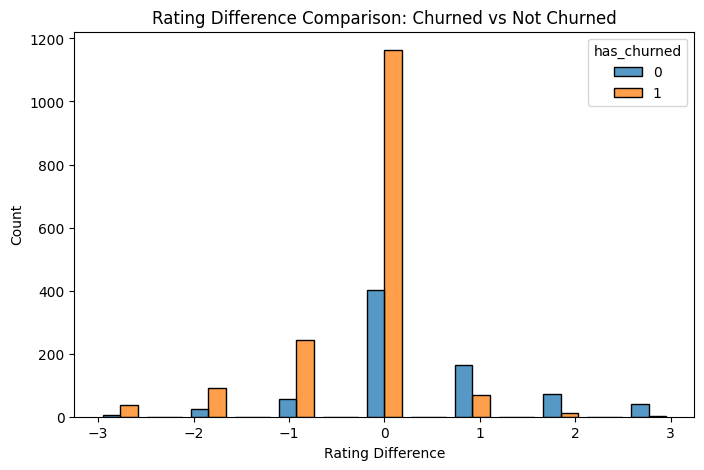

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.histplot(
    data=rating_diff,
    x='rating_difference',
    hue='has_churned',
    multiple='dodge',  # Bars ko overlap karne ki jagah side-by-side rakhta hai
    shrink=0.8         # Bars ke beech clean gap deta hai
)

plt.title('Rating Difference Comparison: Churned vs Not Churned')
plt.xlabel('Rating Difference')
plt.ylabel('Count')
plt.show()

In [ ]:
k=data.groupby("has_churned")["Total Business Value"].sum().reset_index()
k

,has_churned,Total Business Value
0,0,7359779130
1,1,3561253150


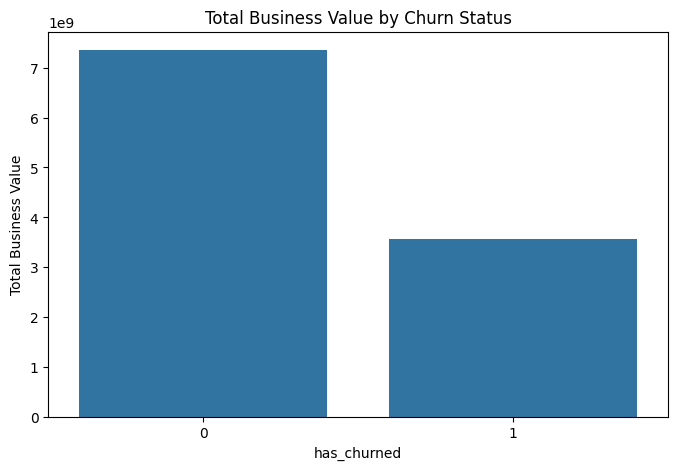

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=k,
    x='has_churned',
    y='Total Business Value')
plt.title('Total Business Value by Churn Status')
plt.show()

In [ ]:
k=data.groupby("has_churned")["Income"].mean().reset_index()
k

,has_churned,Income
0,0,73224.143968
1,1,59259.691959


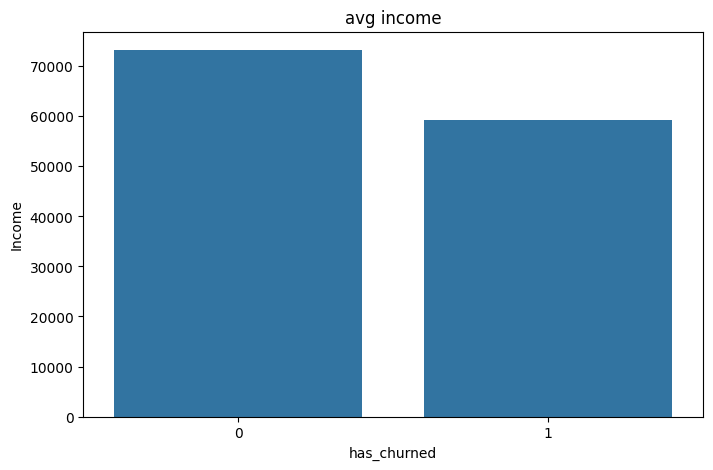

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=k,
    x='has_churned',
    y='Income')
plt.title('avg income')
plt.show()

In [ ]:
bins = [21, 30, 40, 50, 60]
labels = ["21-30", "30-40", "40-50", "50-60"]
data["Groped_age"]=pd.cut(df["Age"],bins=bins,labels=labels)

In [ ]:
p=data.groupby(["Groped_age","has_churned"])["Driver_ID"].nunique().reset_index()
p

/tmp/ipykernel_1668/1438891684.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  p=data.groupby(["Groped_age","has_churned"])["Driver_ID"].nunique().reset_index()


,Groped_age,has_churned,Driver_ID
0,21-30,0,253
1,21-30,1,592
2,30-40,0,461
3,30-40,1,880
4,40-50,0,107
5,40-50,1,205
6,50-60,0,6
7,50-60,1,14


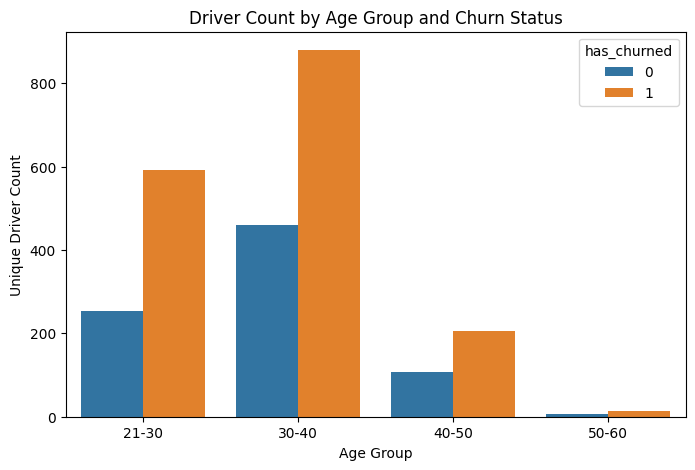

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.barplot(
    data=p,
    x='Groped_age',
    y='Driver_ID',
    hue='has_churned'
)
plt.title('Driver Count by Age Group and Churn Status')
plt.xlabel('Age Group')
plt.ylabel('Unique Driver Count')
plt.show()

In [ ]:
data["first_income"] = data.groupby("Driver_ID")["Income"].transform("first")
data["last_income"] = data.groupby("Driver_ID")["Income"].transform("last")
data["first_quarter_rating"] = data.groupby(["Driver_ID"])["Quarterly Rating"].transform("first")
data["last_quarter_rating"] = data.groupby(["Driver_ID"])["Quarterly Rating"].transform("last")

In [ ]:
data["income_change"] = data["last_income"] - data["first_income"]
data["rating_difference"] = (
    data["last_quarter_rating"] - data["first_quarter_rating"]
)

In [ ]:
data.drop(["first_quarter_rating","last_quarter_rating","first_income","last_income","Groped_age","City"],axis=1,inplace=True)

In [ ]:
data.isnull().sum()

,0
Driver_ID,0
Age,61
Gender,52
Education_Level,0
Income,0
Dateofjoining,0
Joining Designation,0
Grade,0
Total Business Value,0
Quarterly Rating,0


In [ ]:
data["Gender"] = data["Gender"].fillna(data["Gender"].mode()[0])


In [ ]:
data["Month"] = data["MMM-YY_formatted"].dt.month
data["Year"] = data["MMM-YY_formatted"].dt.year


# Helper function for categorical Mode
def get_mode(x):
    m = x.mode()
    return m.iloc[0] if not m.empty else x.iloc[0]


# 6. Aggregate to Driver Level (data_driver)
data_driver = (
    data.groupby("Driver_ID")
    .agg(
        # Demographics
        Age=("Age", "max"),
        Gender=("Gender", get_mode),
        Education_Level=("Education_Level", get_mode),
        # Income & Financial Growth
        Income_Mean=("Income", "mean"),
        Income_Latest=("Income", "last"),
        Income_Change=("income_change", "first"),
        has_churned=("has_churned","first"),
        # Career Trajectory
        Joining_Designation=("Joining Designation", "first"),
        Latest_Grade=("Grade", "last"),
        Grade_Change=("Grade", lambda x: x.iloc[-1] - x.iloc[0]),
        # Revenue & Quarterly Rating Performance
        Total_Business_Value=("Total Business Value", "sum"),
        Avg_Monthly_Business_Value=("Total Business Value", "mean"),
        Initial_Rating=("Quarterly Rating", "first"),
        Latest_Rating=("Quarterly Rating", "last"),
        Rating_Difference=("rating_difference", "first"),
        # Numeric Temporal Conversion (Replaces Datetime Objects)
        Months_Active=("MMM-YY_formatted", "count"),
    )
        )






In [ ]:
data_driver=data_driver.reset_index()

In [ ]:
data_driver.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2381 entries, 0 to 2380
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Driver_ID                   2381 non-null   int64  
 1   Age                         2381 non-null   float64
 2   Gender                      2381 non-null   float64
 3   Education_Level             2381 non-null   int64  
 4   Income_Mean                 2381 non-null   float64
 5   Income_Latest               2381 non-null   int64  
 6   Income_Change               2381 non-null   int64  
 7   has_churned                 2381 non-null   int64  
 8   Joining_Designation         2381 non-null   int64  
 9   Latest_Grade                2381 non-null   int64  
 10  Grade_Change                2381 non-null   int64  
 11  Total_Business_Value        2381 non-null   int64  
 12  Avg_Monthly_Business_Value  2381 non-null   float64
 13  Initial_Rating              2381 

In [ ]:
data_driver.isnull().sum()

,0
Driver_ID,0
Age,0
Gender,0
Education_Level,0
Income_Mean,0
Income_Latest,0
Income_Change,0
has_churned,0
Joining_Designation,0
Latest_Grade,0


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split


# Define X using only numerical columns to avoid DTypePromotionError
X = data_driver.drop(["has_churned","Driver_ID"], axis=1)
y = data_driver["has_churned"]

# 1. Train-Test Split (SMOTE hamesha train data par apply karein, test par NAHIN)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)



In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

# Re-define the param_grid to match the pipeline step prefix 'rf__'
pipeline_param_grid = {
    'rf__n_estimators': [100, 110, 120],
    'rf__max_depth': [8, 15, None],
    'rf__min_samples_leaf': [1, 3, 5],
    'rf__max_features': ['sqrt', 0.5],
    'rf__class_weight': [None, 'balanced']
}

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("rf", RandomForestClassifier(random_state=42))
])

grid = GridSearchCV(pipe, pipeline_param_grid, cv=5, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)
grid.best_score_

np.float64(0.8665095321902367)

In [ ]:
grid.best_params_

{'rf__class_weight': None,
 'rf__max_depth': 8,
 'rf__max_features': 0.5,
 'rf__min_samples_leaf': 3,
 'rf__n_estimators': 120}

In [ ]:
grid.score(X_test,y_test)

np.float64(0.8997014443637538)

In [ ]:
importance = pd.Series(
   grid.best_estimator_.named_steps['rf'].feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# Display top 10 features
print(importance.head(10))

Latest_Rating                 0.248713
Months_Active                 0.222262
Rating_Difference             0.114953
Total_Business_Value          0.083305
Joining_Designation           0.074179
Avg_Monthly_Business_Value    0.060381
Age                           0.055688
Income_Latest                 0.039172
Income_Mean                   0.036830
Latest_Grade                  0.021896
dtype: float64


In [ ]:
from sklearn.metrics import accuracy_score, classification_report
y_pred = grid.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))

Test accuracy: 0.8512
              precision    recall  f1-score   support

    No Churn       0.76      0.78      0.77       153
       Churn       0.89      0.89      0.89       324

    accuracy                           0.85       477
   macro avg       0.83      0.83      0.83       477
weighted avg       0.85      0.85      0.85       477



In [ ]:
from sklearn.ensemble import GradientBoostingClassifier as GBC
from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
import datetime as dt

# Correct the parameter prefixes to match the "gbc" step and remove "class_weight"
pipeline_param_grid = {
    'gbc__n_estimators': [100, 110, 120],
    'gbc__max_depth': [3, 5, 8],
    'gbc__min_samples_leaf': [1, 3, 5],
    'gbc__max_features': ['sqrt', 0.5]
}

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("gbc", GBC(random_state=42))
])
clf = GridSearchCV(pipe, pipeline_param_grid, cv=5, scoring="roc_auc", n_jobs=-1)
clf.fit(X_train, y_train)
clf.best_score_

np.float64(0.870184688288842)

In [ ]:
clf.best_params_

{'gbc__max_depth': 3,
 'gbc__max_features': 0.5,
 'gbc__min_samples_leaf': 5,
 'gbc__n_estimators': 100}

In [ ]:
print("CV ROC-AUC  :", round(clf.best_score_, 4))
print("Test ROC-AUC:", round(clf.score(X_test, y_test), 4))

CV ROC-AUC  : 0.8702
Test ROC-AUC: 0.9062


In [ ]:
from sklearn.metrics import accuracy_score, classification_report
y_pred = clf.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))

Test accuracy: 0.8553
              precision    recall  f1-score   support

    No Churn       0.77      0.78      0.78       153
       Churn       0.89      0.89      0.89       324

    accuracy                           0.86       477
   macro avg       0.83      0.83      0.83       477
weighted avg       0.86      0.86      0.86       477



In [ ]:
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold


pipe_xgb = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(random_state=42, eval_metric="logloss", n_jobs=1))
])

xgb_grid = {
    "xgb__n_estimators": [100, 200],
    "xgb__max_depth": [3, 5],
    "xgb__learning_rate": [0.05, 0.1],
    "xgb__subsample": [0.8, 1.0],
    "xgb__colsample_bytree": [0.8, 1.0],
}

grid_xgb = GridSearchCV(pipe_xgb, xgb_grid, cv=5, scoring="roc_auc", n_jobs=-1)
grid_xgb.fit(X_train, y_train)          # raw X_train

print("Best params:", grid_xgb.best_params_)
print("CV ROC-AUC :", round(grid_xgb.best_score_, 4))

Best params: {'xgb__colsample_bytree': 1.0, 'xgb__learning_rate': 0.05, 'xgb__max_depth': 3, 'xgb__n_estimators': 200, 'xgb__subsample': 1.0}
CV ROC-AUC : 0.8677


In [ ]:
grid_xgb.score(X_test,y_test)

np.float64(0.9036855482933914)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report
y_pred = grid_xgb.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))

Test accuracy: 0.8532
              precision    recall  f1-score   support

    No Churn       0.77      0.76      0.77       153
       Churn       0.89      0.90      0.89       324

    accuracy                           0.85       477
   macro avg       0.83      0.83      0.83       477
weighted avg       0.85      0.85      0.85       477



In [ ]:
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

pipe_lgbm = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("lgbm", LGBMClassifier(random_state=42, n_jobs=1, verbose=-1))
])

lgbm_grid = {
    "lgbm__n_estimators": [100, 200],
    "lgbm__num_leaves": [7, 15, 31],
    "lgbm__learning_rate": [0.05, 0.1],
    "lgbm__min_child_samples": [10, 20],
    "lgbm__subsample": [0.8, 1.0],
}

grid_lgbm = GridSearchCV(pipe_lgbm, lgbm_grid, cv=5, scoring="roc_auc", n_jobs=-1)
grid_lgbm.fit(X_train, y_train)          # raw X_train

print("Best params:", grid_lgbm.best_params_)
print("CV ROC-AUC :", round(grid_lgbm.best_score_, 4))
print("Test ROC-AUC :", round(grid_lgbm.score(X_test, y_test), 4))     #

Best params: {'lgbm__learning_rate': 0.05, 'lgbm__min_child_samples': 10, 'lgbm__n_estimators': 200, 'lgbm__num_leaves': 7, 'lgbm__subsample': 0.8}
CV ROC-AUC : 0.8695
Test ROC-AUC : 0.903


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [ ]:
from sklearn.metrics import accuracy_score, classification_report
y_pred = grid_lgbm.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))

Test accuracy: 0.8553
              precision    recall  f1-score   support

    No Churn       0.79      0.75      0.77       153
       Churn       0.89      0.90      0.89       324

    accuracy                           0.86       477
   macro avg       0.84      0.83      0.83       477
weighted avg       0.85      0.86      0.85       477



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
